In [1]:
pip install pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Total baris: 199319

Jumlah per kelas (semua baris):
label
X    191819
H      3454
A      2577
D      1469
Name: count, dtype: int64

Frame berlabel: 7500 (5.00 menit)
Rentang frame : 11185 sampai 18684

Proporsi per kelas (frame berlabel, %):
label
H    46.05
A    34.36
D    19.59
Name: proportion, dtype: float64

Jumlah segmen per kelas:
label
A    9
H    8
D    4
Name: count, dtype: int64

Jumlah possession (H atau A): 17
Rata-rata durasi possession (detik): 14.19
Terpendek / terpanjang (detik): 0.76 / 42.44

Daftar semua segmen:
   label  start    end  n_frame  durasi_detik
0      A  11185  11350      166          6.64
1      H  11351  11552      202          8.08
2      A  11553  11623       71          2.84
3      H  11624  12664     1041         41.64
4      A  12665  12850      186          7.44
5      D  12851  12988      138          5.52
6      H  12989  13703      715         28.60
7      A  13704  13784       81          3.24
8      H  13785  14845     1061         42.44
9

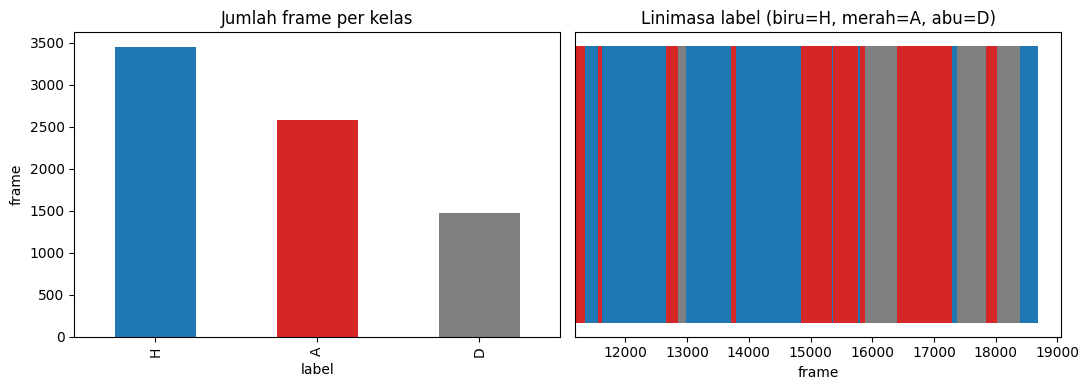

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

PATH = r"evaluation\gt\BAR-ATH_possession_gt_public.csv"
FPS = 25

gt = pd.read_csv(PATH)
gt["label"] = gt["label"].astype(str).str.strip().str.upper()

# 1. Sebaran semua baris
print("Total baris:", len(gt))
print("\nJumlah per kelas (semua baris):")
print(gt["label"].value_counts())

# 2. Hanya frame yang dinilai (bukan X)
g = gt[gt["label"] != "X"].reset_index(drop=True)
print("\nFrame berlabel:", len(g), f"({len(g)/FPS/60:.2f} menit)")
print("Rentang frame :", g["frame"].min(), "sampai", g["frame"].max())

pct = (g["label"].value_counts(normalize=True) * 100).round(2)
print("\nProporsi per kelas (frame berlabel, %):")
print(pct)

# 3. Pecah jadi segmen (deretan label yang sama dan frame berurutan)
run_id = ((g["label"] != g["label"].shift()) | (g["frame"].diff() != 1)).cumsum()
seg = (g.groupby(run_id)
         .agg(label=("label", "first"),
              start=("frame", "min"),
              end=("frame", "max"),
              n_frame=("frame", "size"))
         .reset_index(drop=True))
seg["durasi_detik"] = (seg["n_frame"] / FPS).round(2)

print("\nJumlah segmen per kelas:")
print(seg["label"].value_counts())

poss = seg[seg["label"].isin(["H", "A"])]
print("\nJumlah possession (H atau A):", len(poss))
print("Rata-rata durasi possession (detik):", round(poss["durasi_detik"].mean(), 2))
print("Terpendek / terpanjang (detik):",
      poss["durasi_detik"].min(), "/", poss["durasi_detik"].max())

print("\nDaftar semua segmen:")
print(seg.to_string())

# 4. Grafik
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
g["label"].value_counts().reindex(["H", "A", "D"]).plot.bar(ax=ax[0], color=["#1f77b4", "#d62728", "#7f7f7f"])
ax[0].set_title("Jumlah frame per kelas")
ax[0].set_ylabel("frame")

warna = {"H": "#1f77b4", "A": "#d62728", "D": "#7f7f7f"}
for _, r in seg.iterrows():
    ax[1].barh(0, r["n_frame"], left=r["start"], color=warna[r["label"]])
ax[1].set_yticks([])
ax[1].set_title("Linimasa label (biru=H, merah=A, abu=D)")
ax[1].set_xlabel("frame")
plt.tight_layout()
plt.show()